# Evaluate every model
ROC curve and AUC for CatBoost, LightGBM, XGBoost and the weighted ensemble, plus a confusion matrix for the weighted ensemble.

Run all cells from the project root or from `experiments/`. The first cell runs `4_Weighted_ensemble.ipynb`, which trains all three models with three seeds each, so it takes a few minutes. It also rewrites `submissions/submission_weighted_80_10_10.csv`.

All results use **out-of-fold** probabilities: each labeled passenger is scored by the models from the one fold that did not train on them. Kaggle's test passengers have no labels, so these are the only predictions we can score locally. Positive class = transported.

In [1]:
from pathlib import Path

ENSEMBLE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'raw').is_dir()) / 'experiments' / '4_Weighted_ensemble.ipynb'
%run "{ENSEMBLE}"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


LightGBM 42 finished
LightGBM 73 finished
LightGBM 101 finished
XGBoost 42 finished
XGBoost 73 finished
XGBoost 101 finished
Finished fold 1
Finished fold 2
Finished fold 3
Finished fold 4
Finished fold 5
Finished fold 1
Finished fold 2
Finished fold 3
Finished fold 4
Finished fold 5
Finished fold 1
Finished fold 2
Finished fold 3
Finished fold 4
Finished fold 5
CatBoost    0.813068
Weighted    0.813873
dtype: float64
c:\Users\shaya\titanic-spaceShip\submissions\submission_weighted_80_10_10.csv 4277 passengers
CatBoost reproduction differences: 0
Weighted predictions changed: 38


## ROC curve and AUC
The ROC curve shows the trade-off at every decision threshold, not only at 0.5:

- **True positive rate (y-axis):** share of transported passengers the model finds (recall).
- **False positive rate (x-axis):** share of non-transported passengers wrongly flagged (1 - specificity).

**AUC** is the area under the curve. It is the chance that a random transported passenger scores higher than a random non-transported one: 0.5 is guessing and 1.0 is perfect. The curves sit close together, so the right panel zooms in on the top-left corner where they differ.

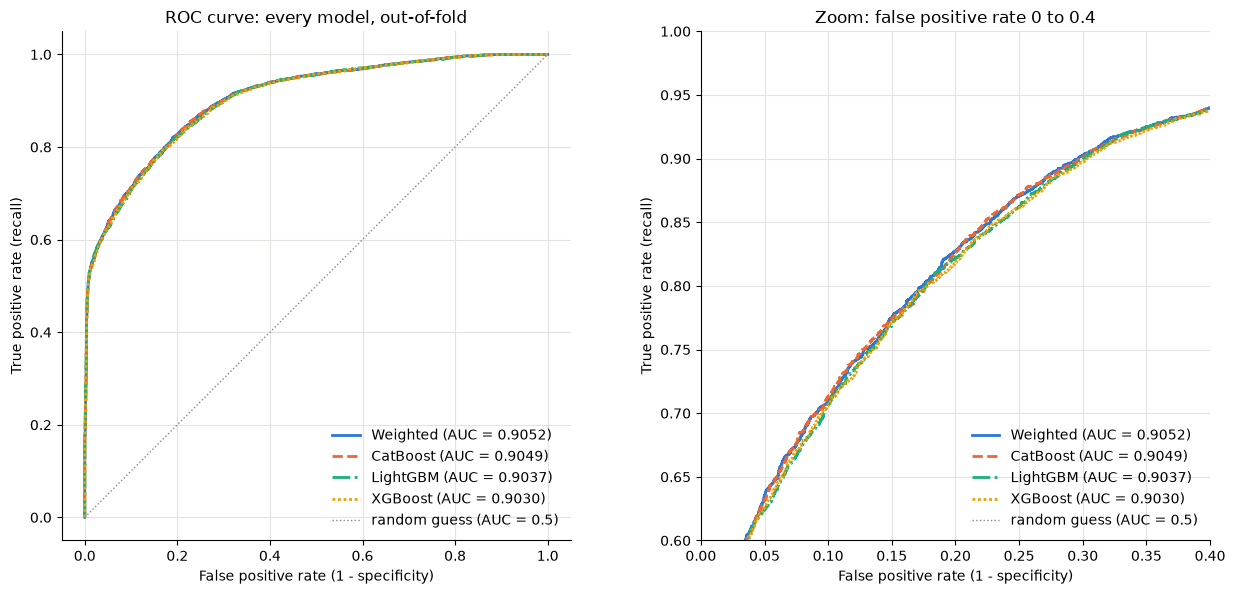

,AUC
Weighted,0.90521
CatBoost,0.90487
LightGBM,0.90370
XGBoost,0.90301


In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

# Each model keeps its own color and line style in every chart
MODEL_STYLES = {
    'Weighted': ('#2a78d6', '-'),
    'CatBoost': ('#eb6834', '--'),
    'LightGBM': ('#1baf7a', '-.'),
    'XGBoost': ('#eda100', (0, (1, 1))),
}


def draw_roc(ax):
    auc = {}
    for name, (color, linestyle) in MODEL_STYLES.items():
        fpr, tpr, _ = roc_curve(y, validation[name])
        auc[name] = roc_auc_score(y, validation[name])
        ax.plot(fpr, tpr, color=color, linestyle=linestyle, linewidth=2, label=f'{name} (AUC = {auc[name]:.4f})')
    ax.plot([0, 1], [0, 1], color='#898781', linewidth=1, linestyle=':', label='random guess (AUC = 0.5)')
    ax.set_xlabel('False positive rate (1 - specificity)')
    ax.set_ylabel('True positive rate (recall)')
    ax.set_aspect('equal')
    ax.grid(color='#e4e3df', linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='lower right', frameon=False)
    return auc


fig, (full, zoom) = plt.subplots(1, 2, figsize=(13, 6))
auc = draw_roc(full)
full.set_title('ROC curve: every model, out-of-fold')
draw_roc(zoom)
zoom.set_xlim(0, .4)
zoom.set_ylim(.6, 1)
zoom.set_title('Zoom: false positive rate 0 to 0.4')
plt.tight_layout()
plt.show()

pd.Series(auc, name='AUC').sort_values(ascending=False).round(5).to_frame()

## Confusion matrix: weighted ensemble
Rows are the true class and columns are the prediction at the 0.5 threshold. The diagonal counts correct predictions.

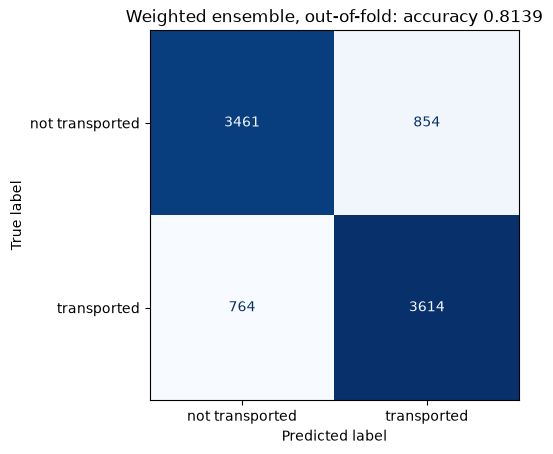

,Weighted
accuracy,0.81387
precision,0.80886
recall (sensitivity),0.82549
specificity,0.80209


In [3]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

matrix = confusion_matrix(y, validation['Weighted'] >= .5, labels=[0, 1])
ConfusionMatrixDisplay(matrix, display_labels=['not transported', 'transported']).plot(
    cmap='Blues', colorbar=False, values_format='d')
plt.title(f'Weighted ensemble, out-of-fold: accuracy {np.trace(matrix) / matrix.sum():.4f}')
plt.show()

tn, fp, fn, tp = matrix.ravel()
pd.Series({
    'accuracy': (tp + tn) / matrix.sum(),
    'precision': tp / (tp + fp),
    'recall (sensitivity)': tp / (tp + fn),
    'specificity': tn / (tn + fp),
}, name='Weighted').round(5).to_frame()